# 05 — EV Business Intelligence: 50-Question Deep Analysis

## Overview
This notebook converts the cleaned EV population dataset into a **business intelligence analysis**.

**Input:** `../datas/cleaned/ev_cleaned.csv`

### Analysis design
- 50 business questions
- Percentage/share analysis
- GroupBy, aggregation, ranking and benchmarking
- Pivot tables and cross-tab analysis
- Feature engineering where meaningful
- Plotly and Altair visualizations
- Cream presentation theme
- Automatic business insight summaries
- No synthetic data
- No machine learning in this notebook

> Every result is calculated from the user's cleaned real-world dataset. The notebook skips analyses when the required column is unavailable.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go
import altair as alt

from IPython.display import display, Markdown

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 01. Load the cleaned dataset

The dataset has already been cleaned and renamed in Notebook 01. This notebook **does not repeat cleaning or column renaming**.


In [2]:
DATA_PATH = Path("../datas/cleaned/ev_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

Shape: (150482, 17)


,VIN,County,City,State,Postal_Code,Model_Year,Make,Model,EV_Type,CAFV_Eligibility,Electric_Range,Base_MSRP,Vehicle_ID,Vehicle_Location,Electric_Utility,Census_Tract,Legislative_District
0,KM8K33AGXL,King,Seattle,WA,98103.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258,0,249675142,POINT (-122.34301 47.659185),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),53033004800.0,43
1,1C4RJYB61N,King,Bothell,WA,98011.0,2022,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,233928502,POINT (-122.20578 47.762405),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033021804.0,1
2,1C4RJYD61P,Yakima,Yakima,WA,98908.0,2023,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,229675939,POINT (-120.6027202 46.5965625),PACIFICORP,53077002900.0,14
3,5YJ3E1EA7J,King,Kirkland,WA,98034.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,104714466,POINT (-122.209285 47.71124),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033021903.0,45
4,WBY7Z8C5XJ,Thurston,Olympia,WA,98501.0,2018,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,97,0,185498386,POINT (-122.89692 47.043535),PUGET SOUND ENERGY INC,53067010700.0,22


## 02. Analysis helpers and presentation theme

The helper functions below make the 50-question analysis reusable and prevent repetitive code.


In [3]:
CREAM = "#F7F0E3"
INK = "#2F2A24"
GRID = "#D8CDBD"

def plotly_theme(fig, title=None):
    fig.update_layout(
        title=title,
        paper_bgcolor=CREAM,
        plot_bgcolor=CREAM,
        font=dict(color=INK),
        margin=dict(l=60, r=30, t=70, b=60),
        hovermode="x unified"
    )
    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(gridcolor=GRID)
    return fig

def pct_table(series, name="Count"):
    out = series.value_counts(dropna=False).rename(name).to_frame()
    out["Percentage"] = (out[name] / out[name].sum() * 100).round(2)
    return out

def show_distribution(column, top_n=15, title=None):
    if column not in df.columns:
        print(f"Skipped: {column} not available.")
        return None
    s = df[column].fillna("Missing").astype(str)
    t = s.value_counts().head(top_n).reset_index()
    t.columns = [column, "Count"]
    t["Percentage"] = (t["Count"] / len(df) * 100).round(2)
    display(t)
    fig = px.bar(t, x=column, y="Count", text="Percentage",
                 title=title or f"Distribution of {column}")
    fig.update_traces(texttemplate="%{text:.2f}%", textposition="outside")
    return plotly_theme(fig)

def numeric_summary(column):
    if column not in df.columns:
        return None
    return df[column].describe().to_frame("Value")

print("Helpers ready.")

Helpers ready.


# Business Question 01 — What is the total EV population represented?

**Purpose:** Establish the overall analytical population.


In [4]:
q01 = len(df)
print(f"Total EV records: {q01:,}")

Total EV records: 150,482


# Business Question 02 — How many unique manufacturers are represented?

**Purpose:** Measure manufacturer diversity.


In [5]:
q02 = df["Make"].nunique()
print(f"Unique manufacturers: {q02:,}")

Unique manufacturers: 37


# Business Question 03 — How many unique EV models are represented?


In [6]:
q03 = df["Model"].nunique()
print(f"Unique models: {q03:,}")

Unique models: 127


# Business Question 04 — Which manufacturers have the largest EV populations?

**Visual:** horizontal Plotly ranking.


,Make,Vehicle_Count,Percentage
0,TESLA,68983,45.84
1,NISSAN,13497,8.97
2,CHEVROLET,12026,7.99
3,FORD,7614,5.06
4,BMW,6439,4.28
5,KIA,6198,4.12
6,TOYOTA,5223,3.47
7,VOLKSWAGEN,4074,2.71
8,VOLVO,3536,2.35
9,JEEP,3292,2.19


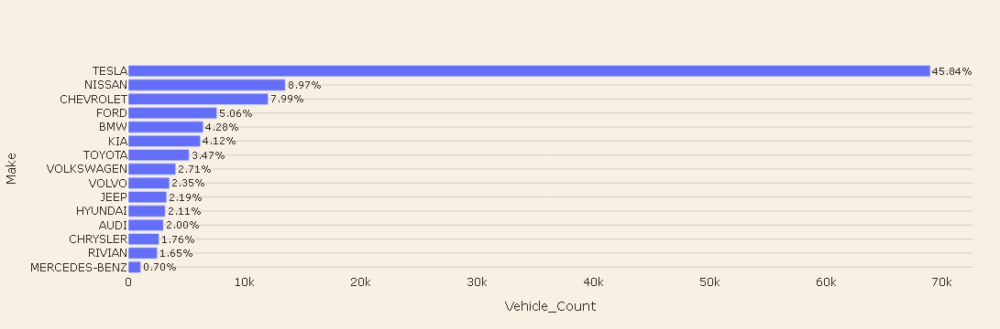

In [7]:
make_counts = pct_table(df["Make"], "Vehicle_Count").reset_index()
make_counts.columns = ["Make", "Vehicle_Count", "Percentage"]
top = make_counts.head(15)

fig = px.bar(top.sort_values("Vehicle_Count"), x="Vehicle_Count", y="Make",
             orientation="h", text="Percentage",
             title="Top EV Manufacturers by Vehicle Population")
fig.update_traces(texttemplate="%{text:.2f}%", textposition="outside")
display(top)
display(plotly_theme(fig))

# Business Question 05 — What is the manufacturer market-share structure?


,Make,Vehicle_Count,Percentage
0,TESLA,68983,45.84
1,NISSAN,13497,8.97
2,CHEVROLET,12026,7.99
3,FORD,7614,5.06
4,BMW,6439,4.28
5,KIA,6198,4.12
6,TOYOTA,5223,3.47
7,VOLKSWAGEN,4074,2.71
8,VOLVO,3536,2.35
9,JEEP,3292,2.19


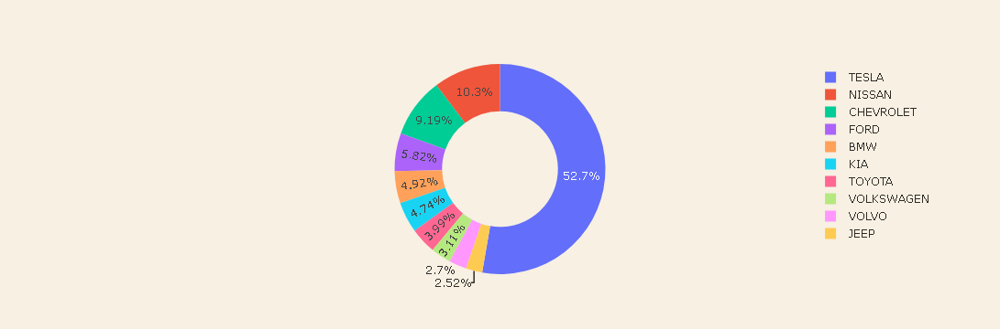

In [8]:
display(make_counts.head(20))

fig = px.pie(make_counts.head(10), names="Make", values="Vehicle_Count",
             hole=0.55, title="Top 10 Manufacturer Share")
display(plotly_theme(fig))

# Business Question 06 — Which EV models are most represented?


,Model,Vehicle_Count,Percentage
0,MODEL Y,28502,18.94
1,MODEL 3,27709,18.41
2,LEAF,13187,8.76
3,MODEL S,7611,5.06
4,BOLT EV,5733,3.81
5,MODEL X,5114,3.40
6,VOLT,4890,3.25
7,ID.4,2999,1.99
8,NIRO,2876,1.91
9,PACIFICA,2642,1.76


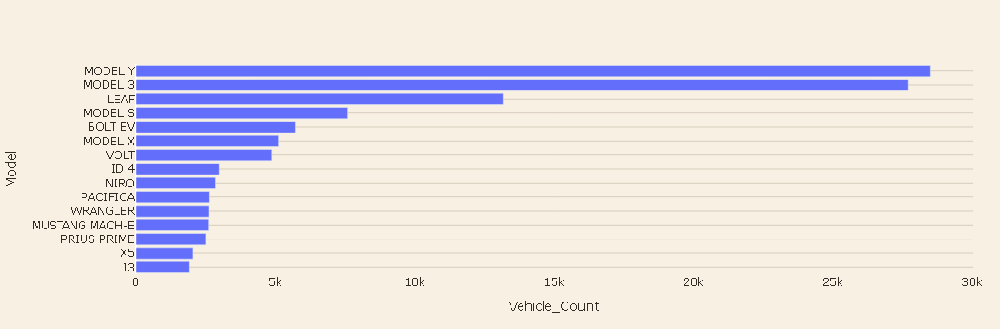

In [9]:
model_counts = pct_table(df["Model"], "Vehicle_Count").reset_index()
model_counts.columns = ["Model", "Vehicle_Count", "Percentage"]
display(model_counts.head(20))

fig = px.bar(model_counts.head(15).sort_values("Vehicle_Count"),
             x="Vehicle_Count", y="Model", orientation="h",
             title="Top EV Models")
display(plotly_theme(fig))

# Business Question 07 — Which manufacturer has the widest model portfolio?


,Make,Unique_Models
0,AUDI,11
1,BMW,11
2,MERCEDES-BENZ,10
3,FORD,8
4,HYUNDAI,8
5,VOLVO,7
6,KIA,7
7,TOYOTA,6
8,TESLA,5
9,CHEVROLET,5


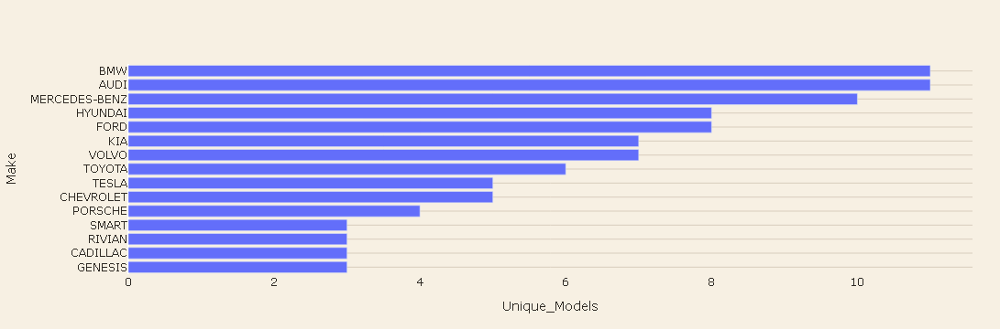

In [10]:
portfolio = (df.groupby("Make")["Model"]
              .nunique()
              .sort_values(ascending=False)
              .rename("Unique_Models")
              .reset_index())
display(portfolio.head(20))

fig = px.bar(portfolio.head(15).sort_values("Unique_Models"),
             x="Unique_Models", y="Make", orientation="h",
             title="Manufacturer Model Portfolio Diversity")
display(plotly_theme(fig))

# Business Question 08 — What is the distribution of EV types?


,EV_Type,Vehicle_Count,Percentage
0,Battery Electric Vehicle (BEV),116807,77.62
1,Plug-in Hybrid Electric Vehicle (PHEV),33675,22.38


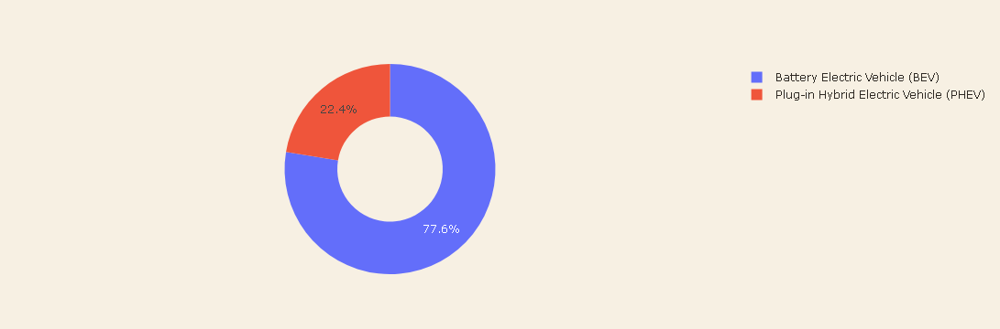

In [11]:
ev_type = pct_table(df["EV_Type"], "Vehicle_Count").reset_index()
ev_type.columns = ["EV_Type", "Vehicle_Count", "Percentage"]
display(ev_type)

fig = px.pie(ev_type, names="EV_Type", values="Vehicle_Count",
             hole=0.5, title="EV Type Composition")
display(plotly_theme(fig))

# Business Question 09 — Which manufacturers dominate each EV type?


EV_Type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV),Total
Make,,,
TESLA,68983,0,68983
NISSAN,13497,0,13497
CHEVROLET,7136,4890,12026
FORD,3908,3706,7614
BMW,1796,4643,6439
KIA,4148,2050,6198
TOYOTA,189,5034,5223
VOLKSWAGEN,4074,0,4074
VOLVO,1181,2355,3536


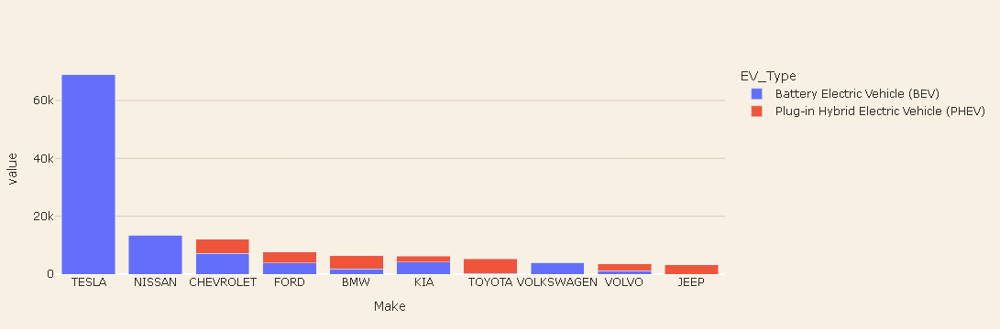

In [12]:
make_evtype = pd.crosstab(df["Make"], df["EV_Type"])
make_evtype["Total"] = make_evtype.sum(axis=1)
display(make_evtype.sort_values("Total", ascending=False).head(20))

top_makes = make_evtype.sort_values("Total", ascending=False).head(10).drop(columns="Total")
fig = px.bar(top_makes, barmode="stack", title="EV Type Mix Across Top Manufacturers")
display(plotly_theme(fig))

# Business Question 10 — How does EV type share vary by manufacturer?

This uses row percentages to compare manufacturers fairly.


EV_Type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV)
Make,,
ALFA ROMEO,0.00,100.00
AUDI,55.29,44.71
AZURE DYNAMICS,100.00,0.00
BENTLEY,0.00,100.00
BMW,27.89,72.11
CADILLAC,47.73,52.27
CHEVROLET,59.34,40.66
CHRYSLER,0.00,100.00
FIAT,100.00,0.00


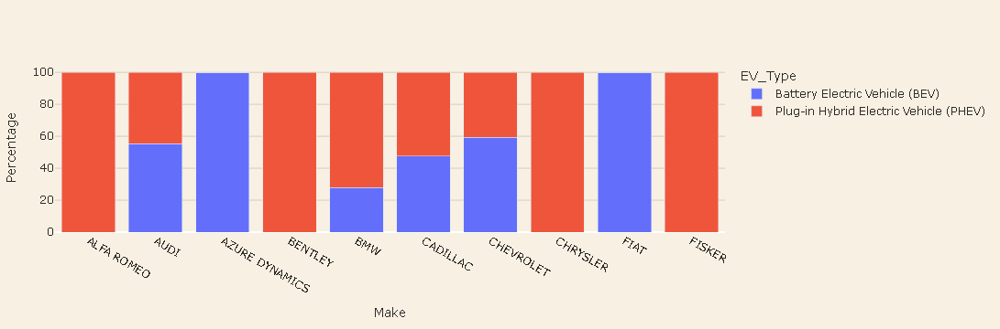

In [13]:
mix = pd.crosstab(df["Make"], df["EV_Type"], normalize="index").mul(100).round(2)
mix["Total"] = mix.sum(axis=1)
display(mix.sort_values("Total", ascending=False).head(15).drop(columns="Total"))

chart_data = mix.sort_values("Total", ascending=False).head(10).drop(columns="Total").reset_index()
long = chart_data.melt(id_vars="Make", var_name="EV_Type", value_name="Percentage")
fig = px.bar(long, x="Make", y="Percentage", color="EV_Type",
             barmode="stack", title="Manufacturer EV Type Mix (%)")
display(plotly_theme(fig))

# Business Question 11 — Which model years contain the largest EV populations?


,Model_Year,Vehicle_Count,Percentage
0,1997,1,0.00
1,1998,1,0.00
2,1999,4,0.00
3,2000,8,0.01
4,2002,2,0.00
5,2003,1,0.00
6,2008,19,0.01
7,2010,24,0.02
8,2011,796,0.53
9,2012,1633,1.09


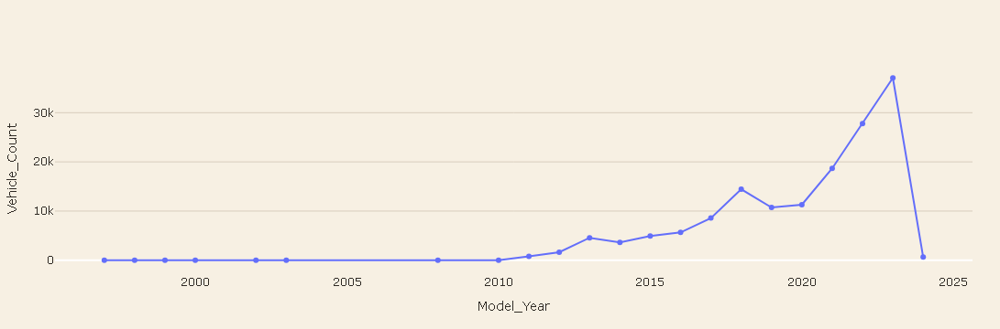

In [14]:
year_counts = df["Model_Year"].value_counts().sort_index().rename("Vehicle_Count").reset_index()
year_counts["Percentage"] = (year_counts["Vehicle_Count"] / len(df) * 100).round(2)
display(year_counts)

fig = px.line(year_counts, x="Model_Year", y="Vehicle_Count",
              markers=True, title="EV Population by Model Year")
display(plotly_theme(fig))

# Business Question 12 — How concentrated is the dataset around newer model years?


,Model_Year,Vehicle_Count,Percentage,Cumulative_%
7,2010,24,0.02,0.04
8,2011,796,0.53,0.57
9,2012,1633,1.09,1.66
10,2013,4566,3.03,4.69
11,2014,3613,2.40,7.09
12,2015,4934,3.28,10.37
13,2016,5650,3.75,14.12
14,2017,8574,5.70,19.82
15,2018,14441,9.60,29.42
16,2019,10717,7.12,36.54


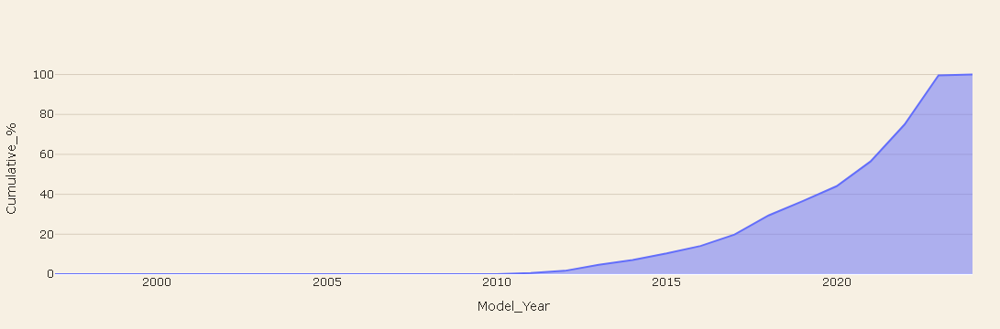

In [15]:
year_counts["Cumulative_%"] = year_counts["Percentage"].cumsum()
display(year_counts.tail(15))

fig = px.area(year_counts, x="Model_Year", y="Cumulative_%",
              title="Cumulative EV Population by Model Year (%)")
display(plotly_theme(fig))

# Business Question 13 — Which states have the largest EV populations?


,State,Vehicle_Count,Percentage
0,WA,150141,99.77
1,CA,92,0.06
2,VA,35,0.02
3,MD,33,0.02
4,TX,20,0.01
5,NC,13,0.01
6,IL,12,0.01
7,AZ,11,0.01
8,CO,11,0.01
9,FL,9,0.01


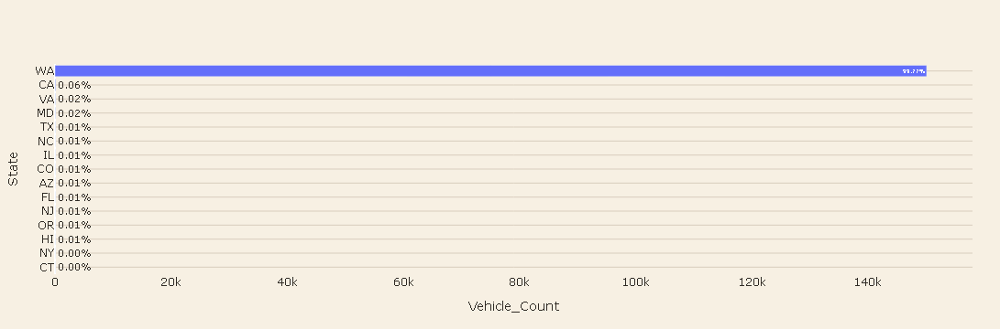

In [16]:
state_counts = pct_table(df["State"], "Vehicle_Count").reset_index()
state_counts.columns = ["State", "Vehicle_Count", "Percentage"]
display(state_counts.head(20))

fig = px.bar(state_counts.head(15).sort_values("Vehicle_Count"),
             x="Vehicle_Count", y="State", orientation="h",
             text="Percentage", title="Top States by EV Population")
fig.update_traces(texttemplate="%{text:.2f}%")
display(plotly_theme(fig))

# Business Question 14 — Which counties have the largest EV populations?


In [17]:
county_counts = pct_table(df["County"], "Vehicle_Count").reset_index()
county_counts.columns = ["County", "Vehicle_Count", "Percentage"]
display(county_counts.head(20))

,County,Vehicle_Count,Percentage
0,King,79078,52.55
1,Snohomish,17307,11.50
2,Pierce,11542,7.67
3,Clark,8855,5.88
4,Thurston,5403,3.59
5,Kitsap,4923,3.27
6,Spokane,3690,2.45
7,Whatcom,3668,2.44
8,Benton,1801,1.20
9,Skagit,1658,1.10


# Business Question 15 — Which cities have the largest EV populations?


In [18]:
city_counts = pct_table(df["City"], "Vehicle_Count").reset_index()
city_counts.columns = ["City", "Vehicle_Count", "Percentage"]
display(city_counts.head(20))

,City,Vehicle_Count,Percentage
0,Seattle,25678,17.06
1,Bellevue,7691,5.11
2,Redmond,5502,3.66
3,Vancouver,5310,3.53
4,Bothell,4861,3.23
5,Kirkland,4622,3.07
6,Sammamish,4436,2.95
7,Renton,4043,2.69
8,Olympia,3634,2.41
9,Tacoma,3121,2.07


# Business Question 16 — How concentrated is EV population across states?

**Interpretation:** High concentration means a smaller set of states accounts for a large share of the observed population.


,State,Vehicle_Count,Percentage,Cumulative_%
0,WA,150141,99.77,99.77
1,CA,92,0.06,99.83
2,VA,35,0.02,99.85
3,MD,33,0.02,99.87
4,TX,20,0.01,99.88
5,NC,13,0.01,99.89
6,IL,12,0.01,99.90
7,AZ,11,0.01,99.91
8,CO,11,0.01,99.92
9,FL,9,0.01,99.93


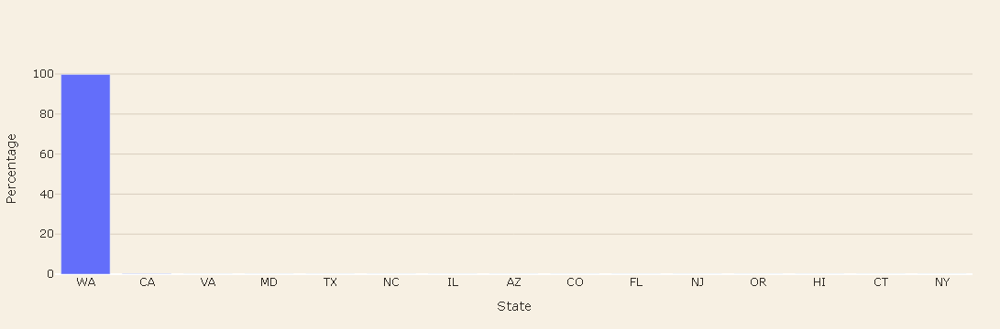

In [19]:
state_counts["Cumulative_%"] = state_counts["Percentage"].cumsum()
display(state_counts.head(20))

fig = px.bar(state_counts.head(15), x="State", y="Percentage",
             title="State EV Population Share (%)")
display(plotly_theme(fig))

# Business Question 17 — Which states have the most diverse manufacturer mix?


,State,Unique_Makes
0,WA,37
1,CA,16
2,MD,14
3,VA,10
4,AZ,8
5,TX,8
6,CO,6
7,CT,6
8,OR,6
9,IL,6


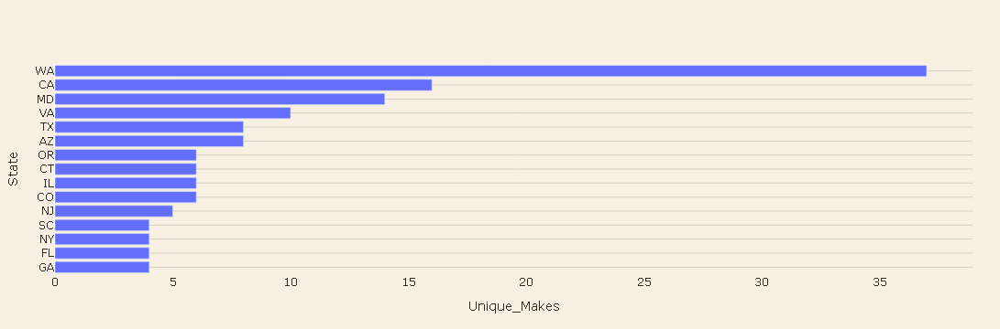

In [20]:
state_make_diversity = (df.groupby("State")["Make"]
                         .nunique()
                         .sort_values(ascending=False)
                         .rename("Unique_Makes")
                         .reset_index())
display(state_make_diversity.head(20))

fig = px.bar(state_make_diversity.head(15).sort_values("Unique_Makes"),
             x="Unique_Makes", y="State", orientation="h",
             title="Manufacturer Diversity by State")
display(plotly_theme(fig))

# Business Question 18 — Which states have the strongest BEV/PHEV mix?


EV_Type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV)
State,,
AK,100.00,0.00
AL,100.00,0.00
AP,100.00,0.00
AR,100.00,0.00
AZ,54.55,45.45
BC,100.00,0.00
CA,66.30,33.70
CO,81.82,18.18
CT,14.29,85.71


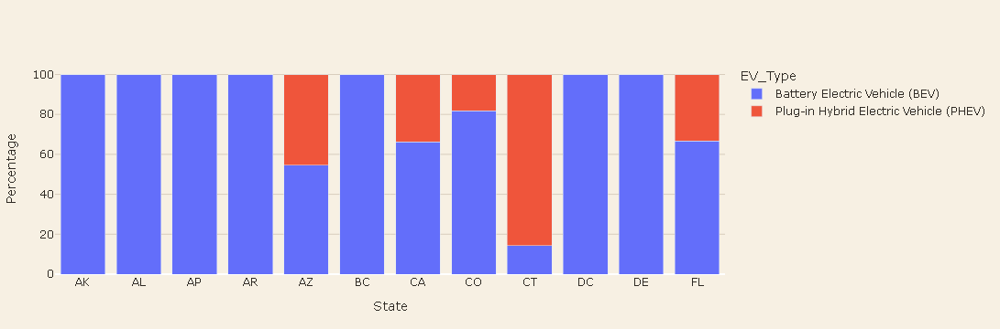

In [21]:
state_type = pd.crosstab(df["State"], df["EV_Type"], normalize="index").mul(100).round(2)
state_type["Total"] = state_type.sum(axis=1)
display(state_type.sort_values("Total", ascending=False).head(20).drop(columns="Total"))

top_states = state_type.sort_values("Total", ascending=False).head(12).drop(columns="Total").reset_index()
long = top_states.melt(id_vars="State", var_name="EV_Type", value_name="Percentage")
fig = px.bar(long, x="State", y="Percentage", color="EV_Type",
             barmode="stack", title="EV Type Mix by State (%)")
display(plotly_theme(fig))

# Business Question 19 — Which EV type is most common in each state?


In [22]:
state_type_counts = pd.crosstab(df["State"], df["EV_Type"])
state_type_counts["Dominant_EV_Type"] = state_type_counts.idxmax(axis=1)
state_type_counts["Dominant_Count"] = state_type_counts.drop(columns="Dominant_EV_Type").max(axis=1)
display(state_type_counts.sort_values("Dominant_Count", ascending=False).head(20))

EV_Type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV),Dominant_EV_Type,Dominant_Count
State,,,,
WA,116585,33556,Battery Electric Vehicle (BEV),116585
CA,61,31,Battery Electric Vehicle (BEV),61
VA,20,15,Battery Electric Vehicle (BEV),20
MD,18,15,Battery Electric Vehicle (BEV),18
TX,14,6,Battery Electric Vehicle (BEV),14
CO,9,2,Battery Electric Vehicle (BEV),9
NC,9,4,Battery Electric Vehicle (BEV),9
IL,9,3,Battery Electric Vehicle (BEV),9
AZ,6,5,Battery Electric Vehicle (BEV),6


# Business Question 20 — Which manufacturers have the highest average electric range?


,Make,Vehicle_Count,Mean_Range,Median_Range,Std_Range
0,JAGUAR,228,204.236842,234.0,78.137775
1,FIAT,806,85.626551,87.0,1.495580
2,NISSAN,13497,84.724902,84.0,51.406537
3,SMART,274,62.375912,58.0,4.974028
4,CHEVROLET,12026,95.267670,53.0,101.246785
5,HONDA,810,46.627160,47.0,3.567364
6,LEXUS,138,22.521739,37.0,18.123348
7,CHRYSLER,2642,32.242998,32.0,0.428975
8,CADILLAC,176,19.079545,31.0,18.386779
9,BMW,6439,38.163379,30.0,37.244576


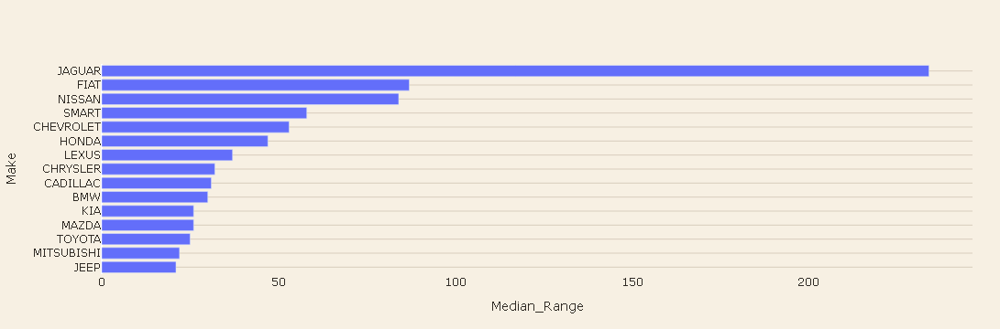

In [23]:
range_make = (df.groupby("Make")["Electric_Range"]
              .agg(["count", "mean", "median", "std"])
              .query("count >= 30")
              .sort_values("median", ascending=False)
              .reset_index())
range_make.columns = ["Make", "Vehicle_Count", "Mean_Range", "Median_Range", "Std_Range"]
display(range_make.head(20))

fig = px.bar(range_make.head(15).sort_values("Median_Range"),
             x="Median_Range", y="Make", orientation="h",
             title="Median Electric Range by Manufacturer")
display(plotly_theme(fig))

# Business Question 21 — Which EV models have the highest electric range?


In [24]:
range_model = (df.groupby(["Make", "Model"])["Electric_Range"]
               .agg(["count", "mean", "median"])
               .query("count >= 10")
               .sort_values("median", ascending=False)
               .reset_index())
display(range_model.head(25))

,Make,Model,count,mean,median
0,HYUNDAI,KONA,208,258.000000,258.0
1,TESLA,ROADSTER,47,234.893617,245.0
2,CHEVROLET,BOLT EV,5733,157.583639,238.0
3,JAGUAR,I-PACE,228,204.236842,234.0
4,TESLA,MODEL 3,27709,121.379444,215.0
5,TESLA,MODEL S,7611,183.456182,208.0
6,AUDI,E-TRON,979,122.696629,204.0
7,TESLA,MODEL X,5114,155.539304,200.0
8,VOLKSWAGEN,E-GOLF,1075,107.379535,125.0
9,TOYOTA,RAV4,60,102.600000,103.0


# Business Question 22 — How is electric range distributed?


,Value
count,150482.000000
mean,67.877839
std,96.230009
min,0.000000
25%,0.000000
50%,18.000000
75%,97.000000
max,337.000000


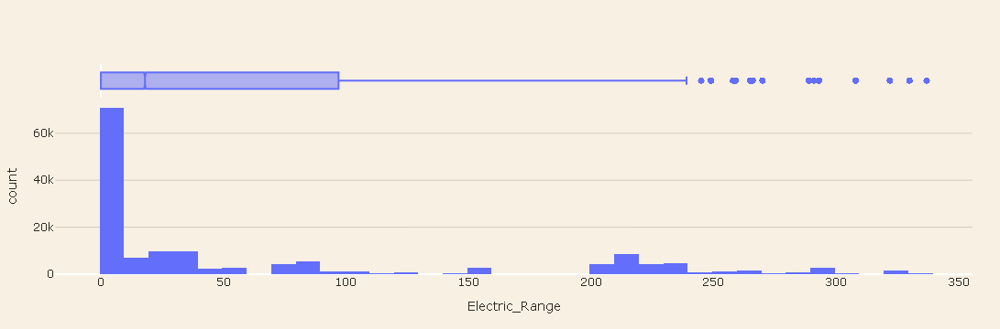

In [25]:
display(numeric_summary("Electric_Range"))

fig = px.histogram(df, x="Electric_Range", nbins=50,
                   marginal="box", title="Electric Range Distribution")
display(plotly_theme(fig))

# Business Question 23 — How does range vary by EV type?


,count,mean,median,std,min,max
EV_Type,,,,,,
Battery Electric Vehicle (BEV),116807,78.61,0.0,106.48,0,337
Plug-in Hybrid Electric Vehicle (PHEV),33675,30.66,26.0,16.46,6,153


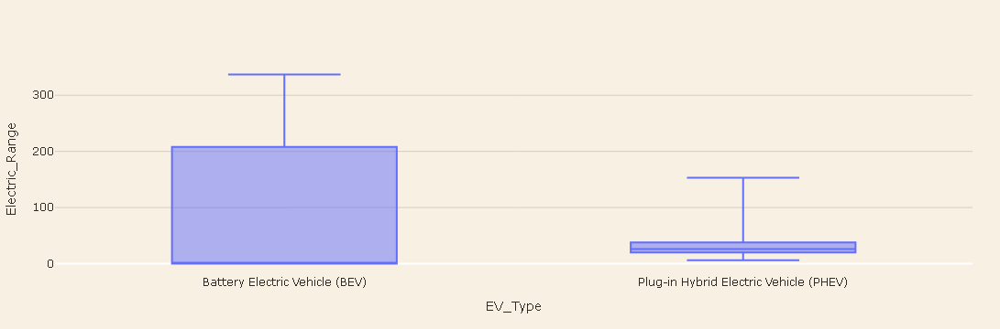

In [26]:
range_type = (df.groupby("EV_Type")["Electric_Range"]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .round(2))
display(range_type)

fig = px.box(df, x="EV_Type", y="Electric_Range",
             points=False, title="Electric Range by EV Type")
display(plotly_theme(fig))

# Business Question 24 — How has median electric range changed by model year?


,Model_Year,count,mean,median
0,1997,1,39.000000,39.0
1,1998,1,58.000000,58.0
2,1999,4,74.000000,74.0
3,2000,8,58.000000,58.0
4,2002,2,95.000000,95.0
5,2003,1,95.000000,95.0
6,2008,19,220.000000,220.0
7,2010,24,226.875000,245.0
8,2011,796,70.851759,73.0
9,2012,1633,62.186160,35.0


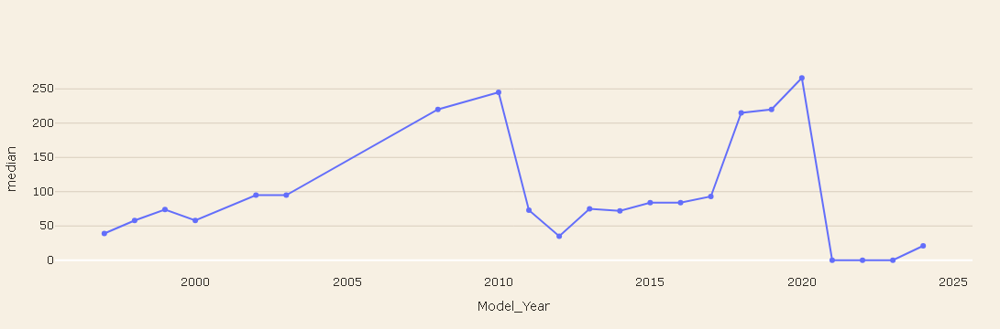

In [27]:
range_year = (df.groupby("Model_Year")["Electric_Range"]
              .agg(["count", "mean", "median"])
              .reset_index())
display(range_year)

fig = px.line(range_year, x="Model_Year", y="median",
              markers=True, title="Median Electric Range by Model Year")
display(plotly_theme(fig))

# Business Question 25 — Which manufacturers combine high volume and high range?

**Visual:** volume vs median range.


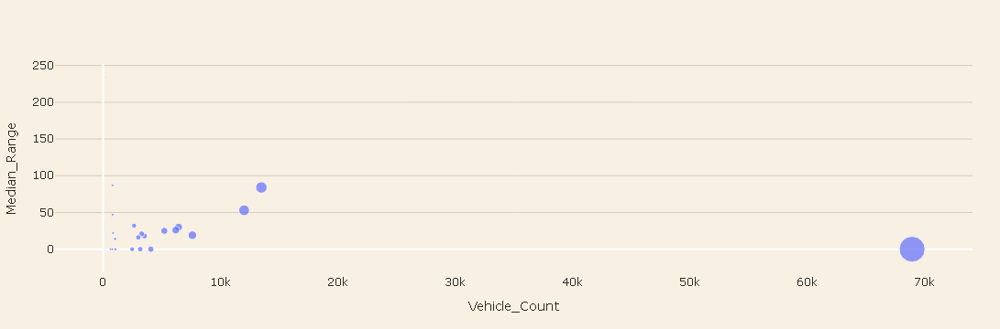

In [28]:
volume_range = make_counts.merge(
    range_make[["Make", "Median_Range"]], on="Make", how="inner"
)
volume_range = volume_range.query("Vehicle_Count >= 30")

fig = px.scatter(volume_range, x="Vehicle_Count", y="Median_Range",
                 size="Vehicle_Count", hover_name="Make",
                 title="Manufacturer Volume vs Median Electric Range")
display(plotly_theme(fig))

# Business Question 26 — What is the MSRP distribution?


,Value
count,150482.000000
mean,1312.644735
std,9231.310215
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,845000.000000


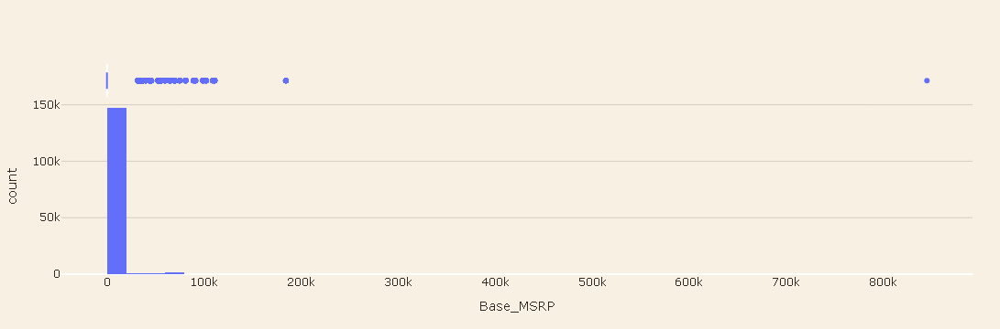

In [29]:
display(numeric_summary("Base_MSRP"))

fig = px.histogram(df, x="Base_MSRP", nbins=60,
                   marginal="box", title="Base MSRP Distribution")
display(plotly_theme(fig))

# Business Question 27 — How many MSRP records are zero?

Zero values must be investigated before treating MSRP as a true price metric.


In [30]:
zero_msrp = (df["Base_MSRP"] == 0).sum()
zero_pct = zero_msrp / len(df) * 100
print(f"Zero MSRP records: {zero_msrp:,} ({zero_pct:.2f}%)")

Zero MSRP records: 147,027 (97.70%)


# Business Question 28 — Which manufacturers have the highest median MSRP among non-zero records?


,Make,count,mean,median
0,FISKER,17,102000.000000,102000.0
1,PORSCHE,31,142396.774194,81100.0
2,CADILLAC,15,75095.000000,75095.0
3,TESLA,1622,70114.364982,69900.0
4,VOLVO,301,56222.757475,52900.0
5,BMW,506,52862.450593,52650.0
6,CHRYSLER,117,39995.000000,39995.0
7,MINI,154,36865.584416,36900.0
8,SUBARU,64,34995.000000,34995.0
9,KIA,625,32259.760000,31950.0


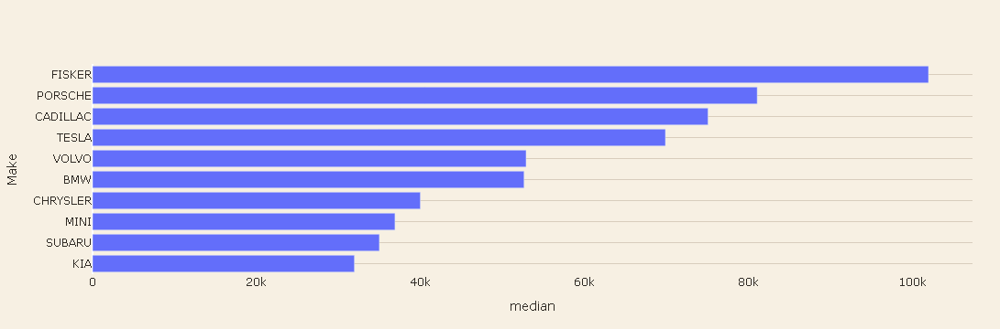

In [31]:
nonzero = df[df["Base_MSRP"] > 0].copy()

if len(nonzero):
    msrp_make = (nonzero.groupby("Make")["Base_MSRP"]
                 .agg(["count", "mean", "median"])
                 .query("count >= 10")
                 .sort_values("median", ascending=False)
                 .reset_index())
    display(msrp_make.head(20))

    fig = px.bar(msrp_make.head(15).sort_values("median"),
                 x="median", y="Make", orientation="h",
                 title="Median MSRP by Manufacturer — Non-Zero Records")
    display(plotly_theme(fig))
else:
    print("No positive MSRP records available.")

# Business Question 29 — Is there a relationship between MSRP and electric range?


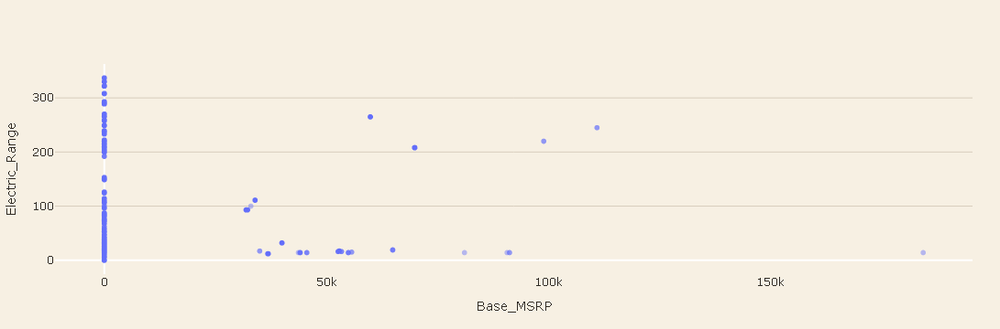

Pearson correlation: 0.1037


In [32]:
corr_data = df[["Base_MSRP", "Electric_Range"]].replace([np.inf, -np.inf], np.nan).dropna()

fig = px.scatter(corr_data.sample(min(10000, len(corr_data)), random_state=42),
                 x="Base_MSRP", y="Electric_Range",
                 opacity=0.45, title="Base MSRP vs Electric Range")
display(plotly_theme(fig))

print("Pearson correlation:", corr_data.corr().iloc[0, 1].round(4))

# Business Question 30 — Which CAFV eligibility categories are most common?


,CAFV_Eligibility,Vehicle_Count,Percentage
0,Eligibility unknown as battery range has not b...,69698,46.32
1,Clean Alternative Fuel Vehicle Eligible,62951,41.83
2,Not eligible due to low battery range,17833,11.85


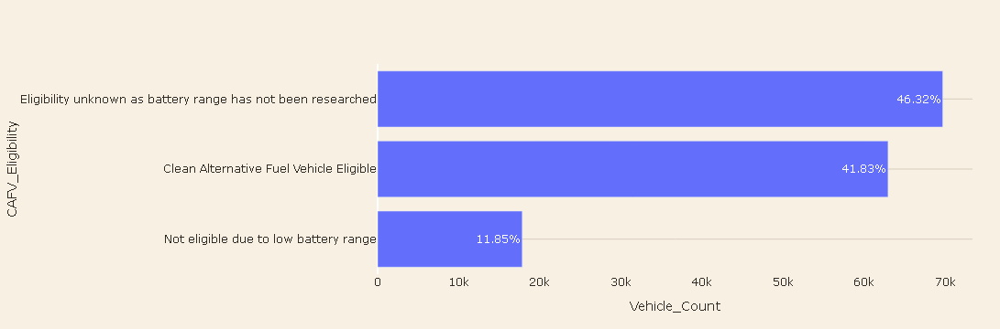

In [33]:
cafv = pct_table(df["CAFV_Eligibility"], "Vehicle_Count").reset_index()
cafv.columns = ["CAFV_Eligibility", "Vehicle_Count", "Percentage"]
display(cafv)

fig = px.bar(cafv.sort_values("Vehicle_Count"), x="Vehicle_Count",
             y="CAFV_Eligibility", orientation="h",
             text="Percentage", title="CAFV Eligibility Distribution")
fig.update_traces(texttemplate="%{text:.2f}%")
display(plotly_theme(fig))

# Business Question 31 — How does CAFV eligibility vary by EV type?


CAFV_Eligibility,Clean Alternative Fuel Vehicle Eligible,Eligibility unknown as battery range has not been researched,Not eligible due to low battery range
EV_Type,,,
Battery Electric Vehicle (BEV),40.32,59.67,0.01
Plug-in Hybrid Electric Vehicle (PHEV),47.07,0.00,52.93


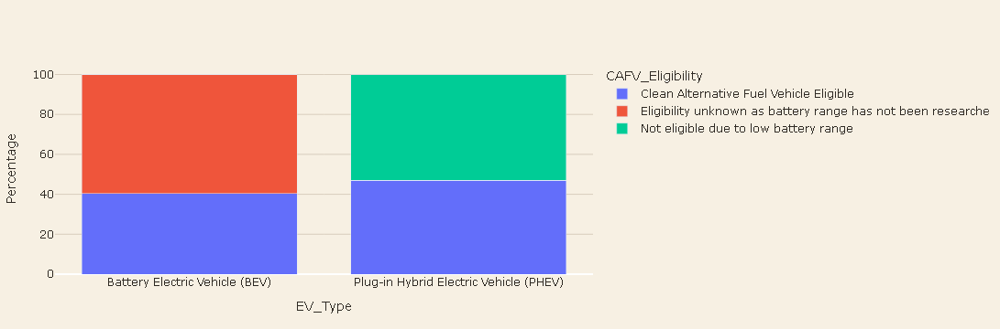

In [34]:
cafv_type = pd.crosstab(df["EV_Type"], df["CAFV_Eligibility"], normalize="index").mul(100).round(2)
display(cafv_type)

long = cafv_type.reset_index().melt(id_vars="EV_Type", var_name="CAFV_Eligibility", value_name="Percentage")
fig = px.bar(long, x="EV_Type", y="Percentage", color="CAFV_Eligibility",
             barmode="stack", title="CAFV Eligibility Mix by EV Type")
display(plotly_theme(fig))

# Business Question 32 — Which manufacturers have the largest CAFV-eligible populations?


In [35]:
eligible_mask = df["CAFV_Eligibility"].astype(str).str.contains("eligible", case=False, na=False)
eligible_make = pct_table(df.loc[eligible_mask, "Make"], "Eligible_Vehicles").reset_index()
eligible_make.columns = ["Make", "Eligible_Vehicles", "Eligible_Share_of_Eligible"]
display(eligible_make.head(20))

,Make,Eligible_Vehicles,Eligible_Share_of_Eligible
0,TESLA,25898,32.06
1,NISSAN,11003,13.62
2,CHEVROLET,8849,10.95
3,BMW,5200,6.44
4,TOYOTA,5094,6.31
5,FORD,3958,4.90
6,KIA,3545,4.39
7,JEEP,3292,4.08
8,CHRYSLER,2642,3.27
9,VOLVO,2355,2.92


# Business Question 33 — What is the CAFV eligibility rate by manufacturer?


,Make,count,mean,Eligibility_Rate_%
4,CHRYSLER,2642,1.000000,100.00
5,FIAT,806,1.000000,100.00
8,HONDA,810,1.000000,100.00
11,JEEP,3292,1.000000,100.00
13,LAND ROVER,47,1.000000,100.00
17,MAZDA,136,1.000000,100.00
15,LINCOLN,229,1.000000,100.00
25,SMART,274,1.000000,100.00
20,MITSUBISHI,849,1.000000,100.00
28,TOYOTA,5223,0.975302,97.53


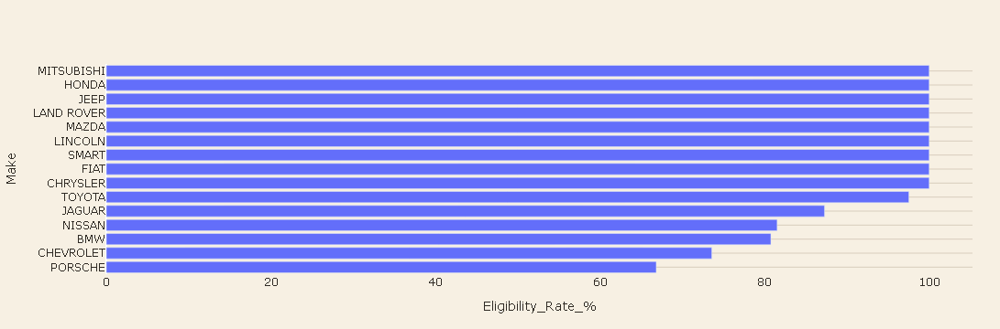

In [36]:
cafv_rate = (df.assign(CAFV_Eligible=eligible_mask)
              .groupby("Make")["CAFV_Eligible"]
              .agg(["count", "mean"])
              .query("count >= 30")
              .reset_index())
cafv_rate["Eligibility_Rate_%"] = (cafv_rate["mean"] * 100).round(2)
cafv_rate = cafv_rate.sort_values("Eligibility_Rate_%", ascending=False)
display(cafv_rate.head(20))

fig = px.bar(cafv_rate.head(15).sort_values("Eligibility_Rate_%"),
             x="Eligibility_Rate_%", y="Make", orientation="h",
             title="CAFV Eligibility Rate by Manufacturer")
display(plotly_theme(fig))

# Business Question 34 — Which states have the highest CAFV eligibility rates?


In [37]:
cafv_state = (df.assign(CAFV_Eligible=eligible_mask)
              .groupby("State")["CAFV_Eligible"]
              .agg(["count", "mean"])
              .query("count >= 30")
              .reset_index())
cafv_state["Eligibility_Rate_%"] = (cafv_state["mean"] * 100).round(2)
cafv_state = cafv_state.sort_values("Eligibility_Rate_%", ascending=False)
display(cafv_state.head(20))

,State,count,mean,Eligibility_Rate_%
2,VA,35,0.742857,74.29
1,MD,33,0.666667,66.67
0,CA,92,0.641304,64.13
3,WA,150141,0.536562,53.66


# Business Question 35 — Which manufacturers have the largest number of distinct vehicle models per state?


In [38]:
make_state = (df.groupby("Make")["State"]
               .nunique()
               .sort_values(ascending=False)
               .rename("States_Present")
               .reset_index())
display(make_state.head(20))

,Make,States_Present
0,TESLA,35
1,CHEVROLET,14
2,NISSAN,13
3,FORD,12
4,TOYOTA,12
5,BMW,11
6,CHRYSLER,11
7,KIA,9
8,JEEP,8
9,VOLKSWAGEN,8


# Business Question 36 — Which cities have the greatest manufacturer diversity?


In [39]:
city_diversity = (df.groupby("City")["Make"]
                 .nunique()
                 .sort_values(ascending=False)
                 .rename("Unique_Makes")
                 .reset_index())
display(city_diversity.head(20))

,City,Unique_Makes
0,Seattle,34
1,Bellingham,33
2,Sammamish,32
3,Redmond,32
4,Bellevue,32
5,Woodinville,32
6,Vancouver,31
7,Bothell,31
8,Olympia,31
9,Spokane,31


# Business Question 37 — Which manufacturer × state combinations have the largest populations?


,State,Make,Vehicle_Count
180,WA,TESLA,68821
174,WA,NISSAN,13481
155,WA,CHEVROLET,12004
159,WA,FORD,7592
153,WA,BMW,6426
165,WA,KIA,6187
182,WA,TOYOTA,5196
183,WA,VOLKSWAGEN,4064
184,WA,VOLVO,3529
164,WA,JEEP,3283


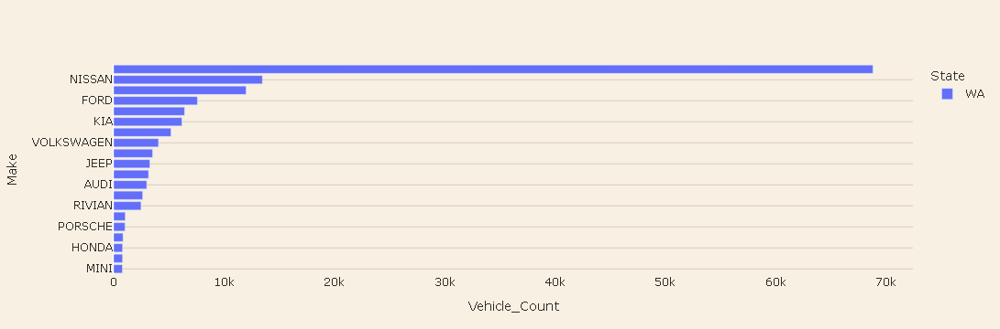

In [40]:
make_state_counts = (df.groupby(["State", "Make"])
                       .size()
                       .rename("Vehicle_Count")
                       .reset_index()
                       .sort_values("Vehicle_Count", ascending=False))
display(make_state_counts.head(30))

fig = px.bar(make_state_counts.head(20).sort_values("Vehicle_Count"),
             x="Vehicle_Count", y="Make", color="State",
             orientation="h", title="Top Manufacturer-State Combinations")
display(plotly_theme(fig))

# Business Question 38 — What does the State × EV Type heatmap show?


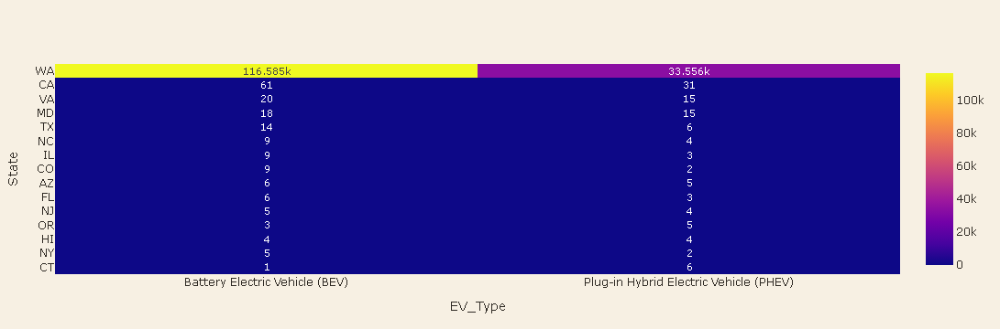

In [41]:
heat = pd.crosstab(df["State"], df["EV_Type"])
top_state_names = heat.sum(axis=1).sort_values(ascending=False).head(15).index
heat = heat.loc[top_state_names]

fig = px.imshow(heat, aspect="auto", text_auto=True,
                title="EV Population Heatmap — State × EV Type")
display(plotly_theme(fig))

# Business Question 39 — What does the Manufacturer × EV Type heatmap show?


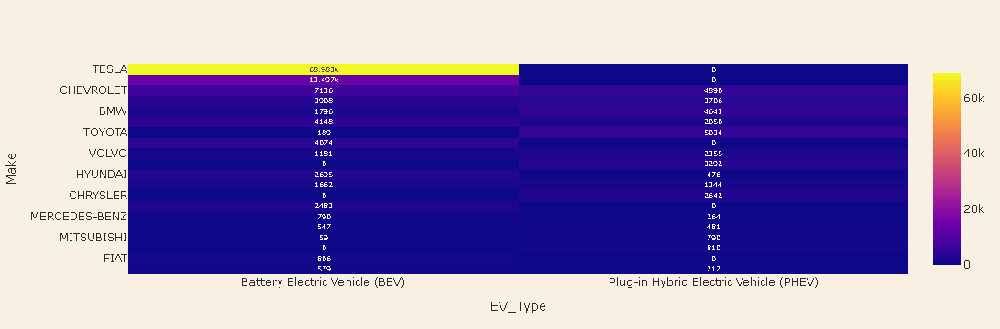

In [42]:
heat2 = pd.crosstab(df["Make"], df["EV_Type"])
top_make_names = heat2.sum(axis=1).sort_values(ascending=False).head(20).index
heat2 = heat2.loc[top_make_names]

fig = px.imshow(heat2, aspect="auto", text_auto=True,
                title="EV Population Heatmap — Manufacturer × EV Type")
display(plotly_theme(fig))

# Business Question 40 — Which model years are strongest within each EV type?


EV_Type,Battery Electric Vehicle (BEV),Plug-in Hybrid Electric Vehicle (PHEV)
Model_Year,,
1999,4,0
2000,8,0
2002,2,0
2003,1,0
2008,19,0
2010,21,3
2011,718,78
2012,776,857
2013,2927,1639


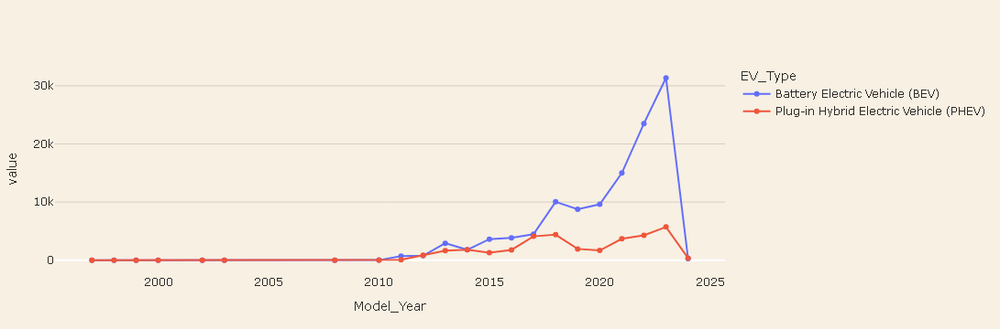

In [43]:
year_type = pd.crosstab(df["Model_Year"], df["EV_Type"])
display(year_type.tail(20))

fig = px.line(year_type, x=year_type.index, y=year_type.columns,
              markers=True, title="EV Type Population by Model Year")
display(plotly_theme(fig))

# Business Question 41 — What is the annual manufacturer concentration?


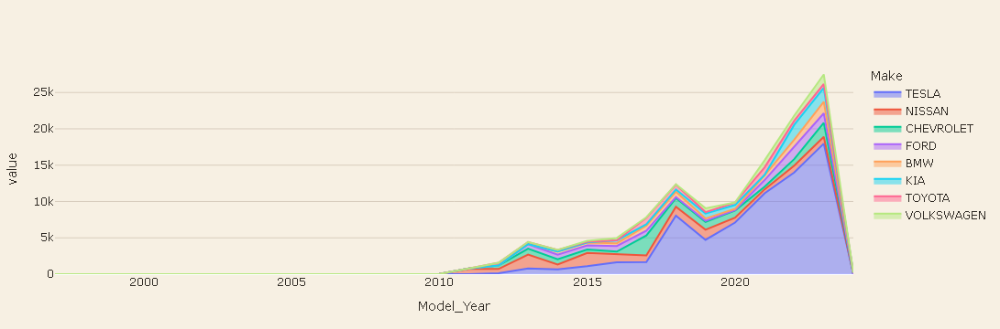

In [44]:
top_make_names = df["Make"].value_counts().head(8).index
annual_make = pd.crosstab(df["Model_Year"], df["Make"])
annual_make = annual_make.reindex(columns=top_make_names, fill_value=0)

fig = px.area(annual_make, x=annual_make.index, y=annual_make.columns,
              title="Top Manufacturer Population Across Model Years")
display(plotly_theme(fig))

# Business Question 42 — What is the Pareto concentration of manufacturers?


,Vehicle_Count,Share_%,Cumulative_%
Make,,,
TESLA,68983,45.841363,45.841363
NISSAN,13497,8.969179,54.810542
CHEVROLET,12026,7.991653,62.802196
FORD,7614,5.059741,67.861937
BMW,6439,4.278917,72.140854
KIA,6198,4.118765,76.259619
TOYOTA,5223,3.470847,79.730466
VOLKSWAGEN,4074,2.707301,82.437767
VOLVO,3536,2.349783,84.787549


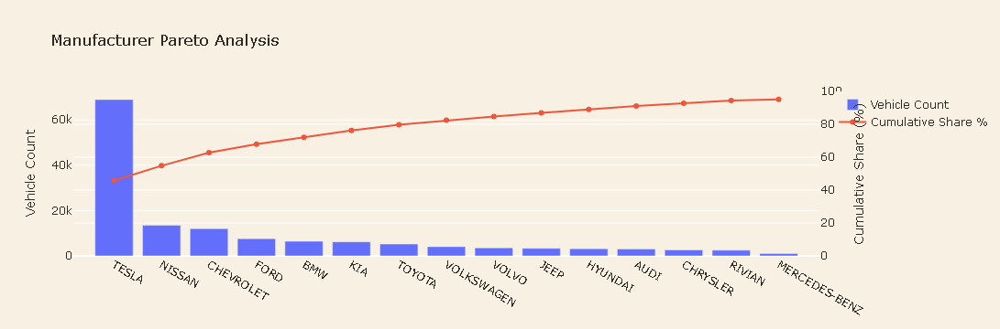

In [45]:
pareto = df["Make"].value_counts().rename("Vehicle_Count").to_frame()
pareto["Share_%"] = pareto["Vehicle_Count"] / pareto["Vehicle_Count"].sum() * 100
pareto["Cumulative_%"] = pareto["Share_%"].cumsum()

display(pareto.head(20))

fig = go.Figure()
fig.add_bar(x=pareto.head(15).index, y=pareto.head(15)["Vehicle_Count"], name="Vehicle Count")
fig.add_scatter(x=pareto.head(15).index, y=pareto.head(15)["Cumulative_%"],
                name="Cumulative Share %", yaxis="y2", mode="lines+markers")
fig.update_layout(
    title="Manufacturer Pareto Analysis",
    paper_bgcolor=CREAM, plot_bgcolor=CREAM, font=dict(color=INK),
    yaxis=dict(title="Vehicle Count"),
    yaxis2=dict(title="Cumulative Share (%)", overlaying="y", side="right", range=[0, 100])
)
display(fig)

# Business Question 43 — What is the average vehicle age by manufacturer?

The reference year is explicitly defined rather than silently assuming today's date.


,Make,count,mean,median
0,FIAT,806,8.531017,9.0
1,SMART,274,8.441606,9.0
2,NISSAN,13497,7.223902,8.0
3,HONDA,810,5.676543,6.0
4,CADILLAC,176,4.954545,6.0
5,CHEVROLET,12026,5.812490,6.0
6,JAGUAR,228,4.289474,5.0
7,TOYOTA,5223,5.448593,5.0
8,MITSUBISHI,849,4.009423,4.0
9,LAND ROVER,47,3.510638,4.0


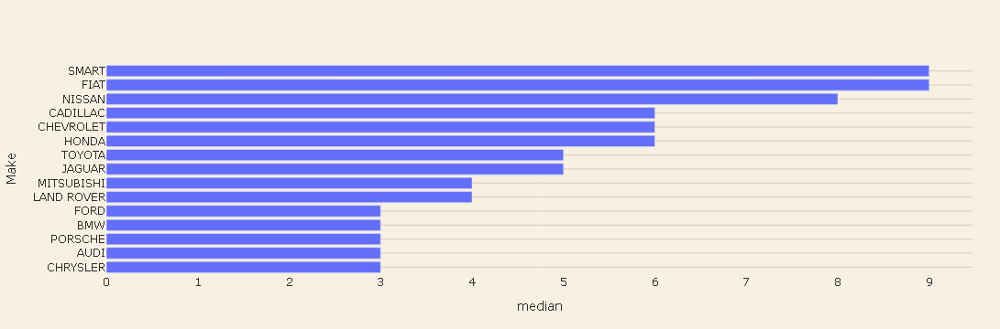

In [46]:
REFERENCE_YEAR = int(df["Model_Year"].max())
df["Vehicle_Age"] = REFERENCE_YEAR - df["Model_Year"]

age_make = (df.groupby("Make")["Vehicle_Age"]
            .agg(["count", "mean", "median"])
            .query("count >= 30")
            .sort_values("median", ascending=False)
            .reset_index())
display(age_make.head(20))

fig = px.bar(age_make.head(15).sort_values("median"),
             x="median", y="Make", orientation="h",
             title=f"Median Vehicle Age by Manufacturer — Reference Year {REFERENCE_YEAR}")
display(plotly_theme(fig))

# Business Question 44 — How is vehicle age distributed?


,Vehicle_Age
count,150482.000000
mean,3.994564
std,3.015209
min,0.000000
25%,1.000000
50%,3.000000
75%,6.000000
max,27.000000


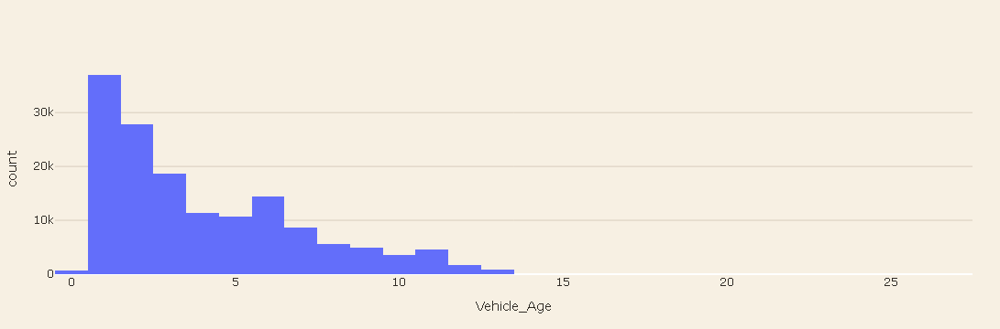

In [47]:
display(df["Vehicle_Age"].describe().to_frame("Vehicle_Age"))

fig = px.histogram(df, x="Vehicle_Age", nbins=30,
                   title=f"Vehicle Age Distribution — Reference Year {REFERENCE_YEAR}")
display(plotly_theme(fig))

# Business Question 45 — Which manufacturers have both newer fleets and large populations?


In [49]:
# Create Vehicle Age
current_year = pd.Timestamp.now().year

df["Vehicle_Age"] = (
    current_year - df["Model_Year"]
).clip(lower=0)

# Manufacturer-wise median vehicle age
age_make = (
    df.groupby("Make")
      .agg(
          Median_Age=("Vehicle_Age", "median")
      )
      .reset_index()
)

# Merge manufacturer volume + median age
age_volume = make_counts.merge(
    age_make[["Make", "Median_Age"]],
    on="Make",
    how="inner"
)

# Keep manufacturers with meaningful sample size
age_volume = age_volume.query("Vehicle_Count >= 30")

display(age_volume.head(20))

,Make,Vehicle_Count,Percentage,Median_Age
0,TESLA,68983,45.84,5.0
1,NISSAN,13497,8.97,10.0
2,CHEVROLET,12026,7.99,8.0
3,FORD,7614,5.06,5.0
4,BMW,6439,4.28,5.0
5,KIA,6198,4.12,4.0
6,TOYOTA,5223,3.47,7.0
7,VOLKSWAGEN,4074,2.71,5.0
8,VOLVO,3536,2.35,4.0
9,JEEP,3292,2.19,3.0


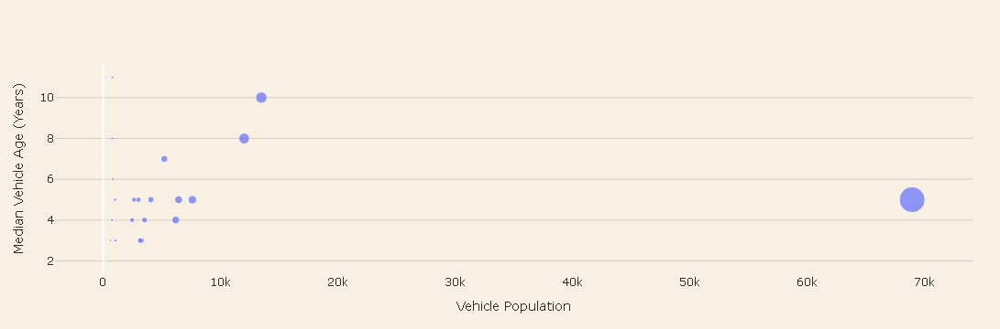

In [50]:
fig = px.scatter(
    age_volume,
    x="Vehicle_Count",
    y="Median_Age",
    size="Vehicle_Count",
    hover_name="Make",
    title="Manufacturer Volume vs Median Vehicle Age",
    labels={
        "Vehicle_Count": "Vehicle Population",
        "Median_Age": "Median Vehicle Age (Years)"
    }
)

display(plotly_theme(fig))

# Business Question 46 — Which states have the highest median electric range?


,State,count,mean,median
0,VA,35,73.114286,32.0
1,MD,33,57.363636,30.0
2,CA,92,69.195652,22.0
3,WA,150141,67.863135,18.0


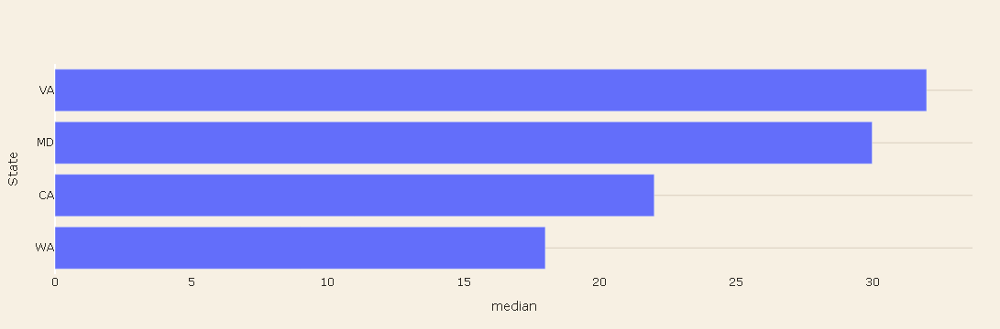

In [51]:
state_range = (df.groupby("State")["Electric_Range"]
               .agg(["count", "mean", "median"])
               .query("count >= 30")
               .sort_values("median", ascending=False)
               .reset_index())
display(state_range.head(20))

fig = px.bar(state_range.head(15).sort_values("median"),
             x="median", y="State", orientation="h",
             title="Median Electric Range by State")
display(plotly_theme(fig))

# Business Question 47 — Which states combine high EV population with high median range?


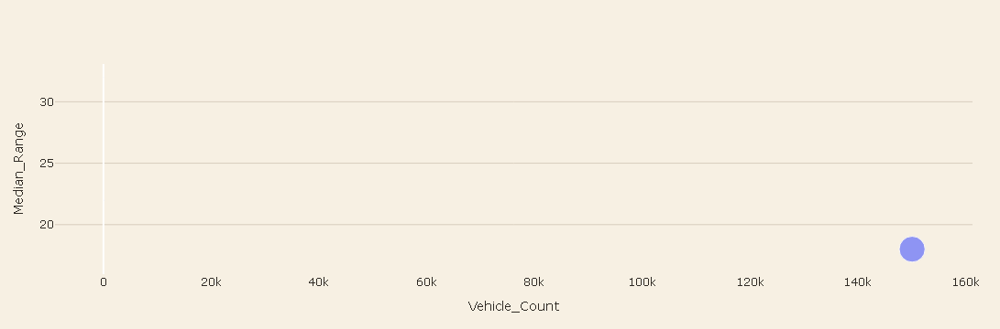

In [52]:
state_volume_range = state_counts.merge(
    state_range[["State", "median"]], on="State", how="inner"
).rename(columns={"median": "Median_Range"})

fig = px.scatter(state_volume_range, x="Vehicle_Count", y="Median_Range",
                 size="Vehicle_Count", hover_name="State",
                 title="State EV Population vs Median Electric Range")
display(plotly_theme(fig))

# Business Question 48 — What are the strongest manufacturer–model combinations?


In [53]:
make_model = (df.groupby(["Make", "Model"])
                .size()
                .rename("Vehicle_Count")
                .reset_index()
                .sort_values("Vehicle_Count", ascending=False))
make_model["Market_Share_%"] = (make_model["Vehicle_Count"] / len(df) * 100).round(2)
display(make_model.head(30))

,Make,Model,Vehicle_Count,Market_Share_%
108,TESLA,MODEL Y,28502,18.94
105,TESLA,MODEL 3,27709,18.41
91,NISSAN,LEAF,13187,8.76
106,TESLA,MODEL S,7611,5.06
30,CHEVROLET,BOLT EV,5733,3.81
107,TESLA,MODEL X,5114,3.40
33,CHEVROLET,VOLT,4890,3.25
118,VOLKSWAGEN,ID.4,2999,1.99
62,KIA,NIRO,2876,1.91
34,CHRYSLER,PACIFICA,2642,1.76


# Business Question 49 — Can Altair provide an additional analytical view?

Altair is used here for a clean interactive categorical comparison. The data itself remains unchanged.


In [54]:
alt_data = make_counts.head(15).copy()

alt_chart = (
    alt.Chart(alt_data)
    .mark_bar()
    .encode(
        x=alt.X("Vehicle_Count:Q", title="Vehicle count"),
        y=alt.Y("Make:N", sort="-x", title="Manufacturer"),
        tooltip=[
            alt.Tooltip("Make:N", title="Manufacturer"),
            alt.Tooltip("Vehicle_Count:Q", title="Vehicles"),
            alt.Tooltip("Percentage:Q", title="Share", format=".2f")
        ]
    )
    .properties(
        title="Altair View — Top EV Manufacturers",
        width=800,
        height=450
    )
)
display(alt_chart)

alt.Chart(...)

# Business Question 50 — What are the final executive-level findings?

The final summary combines the strongest descriptive signals produced above.


In [55]:
top_make = make_counts.iloc[0]
top_state = state_counts.iloc[0]
top_model = model_counts.iloc[0]
top_type = ev_type.iloc[0]

summary = pd.DataFrame({
    "Metric": [
        "Total EV records",
        "Unique manufacturers",
        "Unique models",
        "Top manufacturer",
        "Top state",
        "Top model",
        "Dominant EV type",
        "Average electric range",
        "Median electric range",
        "Reference year"
    ],
    "Value": [
        f"{len(df):,}",
        f"{df['Make'].nunique():,}",
        f"{df['Model'].nunique():,}",
        f"{top_make['Make']} ({top_make['Percentage']:.2f}%)",
        f"{top_state['State']} ({top_state['Percentage']:.2f}%)",
        f"{top_model['Model']} ({top_model['Percentage']:.2f}%)",
        f"{top_type['EV_Type']} ({top_type['Percentage']:.2f}%)",
        f"{df['Electric_Range'].mean():.2f}",
        f"{df['Electric_Range'].median():.2f}",
        str(REFERENCE_YEAR)
    ]
})

display(summary)

,Metric,Value
0,Total EV records,"150,482"
1,Unique manufacturers,37
2,Unique models,127
3,Top manufacturer,TESLA (45.84%)
4,Top state,WA (99.77%)
5,Top model,MODEL Y (18.94%)
6,Dominant EV type,Battery Electric Vehicle (BEV) (77.62%)
7,Average electric range,67.88
8,Median electric range,18.00
9,Reference year,2024


# Executive Insight Summary

Use the following structure in the final report:

### 1. Market structure
Identify whether the observed EV population is concentrated among a small number of manufacturers.

### 2. Geographic structure
Highlight leading states, counties and cities, and compare geographic concentration with manufacturer diversity.

### 3. Technology mix
Compare BEV/PHEV composition and how the mix changes by manufacturer, state and model year.

### 4. Vehicle capability
Use median electric range rather than only the mean when comparing manufacturers and states.

### 5. Price intelligence
Treat zero MSRP separately and avoid interpreting unavailable price records as actual zero-priced vehicles.

### 6. Eligibility
Compare CAFV eligibility across EV types, manufacturers and states.

### 7. Portfolio strategy
Use volume, model diversity, range and vehicle age together rather than ranking manufacturers using only one metric.

### 8. Decision-making
Translate each finding into a possible action for manufacturers, charging providers, investors or policymakers.

> **Important:** This notebook describes patterns in the available dataset. It does not claim that vehicle counts equal total market sales or total real-world registrations unless the source definition explicitly supports that interpretation.


# Final Analytical Deliverables

The notebook produces:

- 50 business questions
- KPI summary
- Market-share tables
- Percentage analysis
- Manufacturer rankings
- Model rankings
- State/county/city rankings
- EV-type analysis
- Model-year trends
- Range intelligence
- MSRP analysis
- CAFV analysis
- Cross-tabulations
- Pivot-style summaries
- Heatmaps
- Pareto analysis
- Scatter analysis
- Plotly charts
- Altair chart
- Feature engineering for vehicle age
- Executive summary

## Next notebook

**Notebook 06 — EV Data Visualization & Storytelling Dashboard**

Focus:
- publication-quality chart library
- advanced Plotly
- advanced Altair
- interactive filters
- dashboard-ready datasets
- business storytelling
- exportable figures and tables
